In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from collections import Counter

print("Library berhasil diimport!")

Library berhasil diimport!


In [3]:
DATASET_DIR = Path("C:\Website\DSC\Dataset DSC GelarRasa 2026")

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test" 

In [4]:
IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

train_paths = sorted([
    p for p in TRAIN_DIR.rglob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

test_paths = sorted([
    p for p in TEST_DIR.rglob("*")
    if p.suffix.lower() in IMAGE_EXTENSIONS
])

print("Jumlah gambar train:", len(train_paths))
print("Jumlah gambar test:", len(test_paths))
print("Total gambar:", len(train_paths) + len(test_paths))

Jumlah gambar train: 1920
Jumlah gambar test: 480
Total gambar: 2400


In [5]:
def check_images(image_paths):
    corrupted = []

    for path in image_paths:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupted.append(path)

    return corrupted


corrupted_train = check_images(train_paths)
corrupted_test = check_images(test_paths)

print("Gambar train rusak:", len(corrupted_train))
print("Gambar test rusak:", len(corrupted_test))

Gambar train rusak: 0
Gambar test rusak: 0


In [6]:
image_sizes = []
image_formats = []

for path in train_paths:
    with Image.open(path) as img:
        image_sizes.append(img.size)
        image_formats.append(img.format)

print("Variasi ukuran gambar:", len(set(image_sizes)))

print("\nDistribusi ukuran:")
for size, count in Counter(image_sizes).most_common(10):
    print(size, ":", count)

print("\nDistribusi format:")
for fmt, count in Counter(image_formats).items():
    print(fmt, ":", count)

Variasi ukuran gambar: 165

Distribusi ukuran:
(640, 640) : 700
(416, 416) : 579
(400, 533) : 74
(640, 480) : 74
(1599, 1599) : 57
(320, 320) : 56
(225, 225) : 39
(400, 534) : 36
(512, 384) : 35
(275, 183) : 30

Distribusi format:
JPEG : 1918
PNG : 2


In [7]:
def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img = np.array(img, dtype=np.float32)

    return img

In [8]:
image_path = train_paths[0]

original_image = Image.open(image_path).convert("RGB")
processed_image = preprocess_image(image_path)

print("Nama gambar:", image_path.name)
print("Ukuran gambar:", processed_image.shape)
print("Tipe data:", processed_image.dtype)

Nama gambar: 0001.jpg
Ukuran gambar: (224, 224, 3)
Tipe data: float32


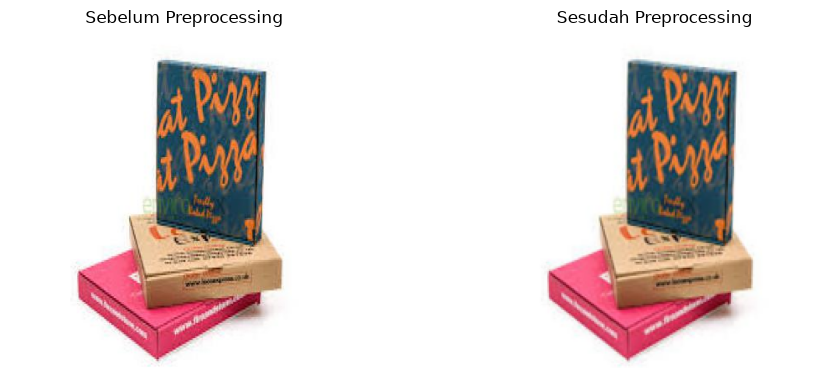

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Sebelum Preprocessing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image.astype(np.uint8))
plt.title("Sesudah Preprocessing")
plt.axis("off")

plt.tight_layout()
plt.show()

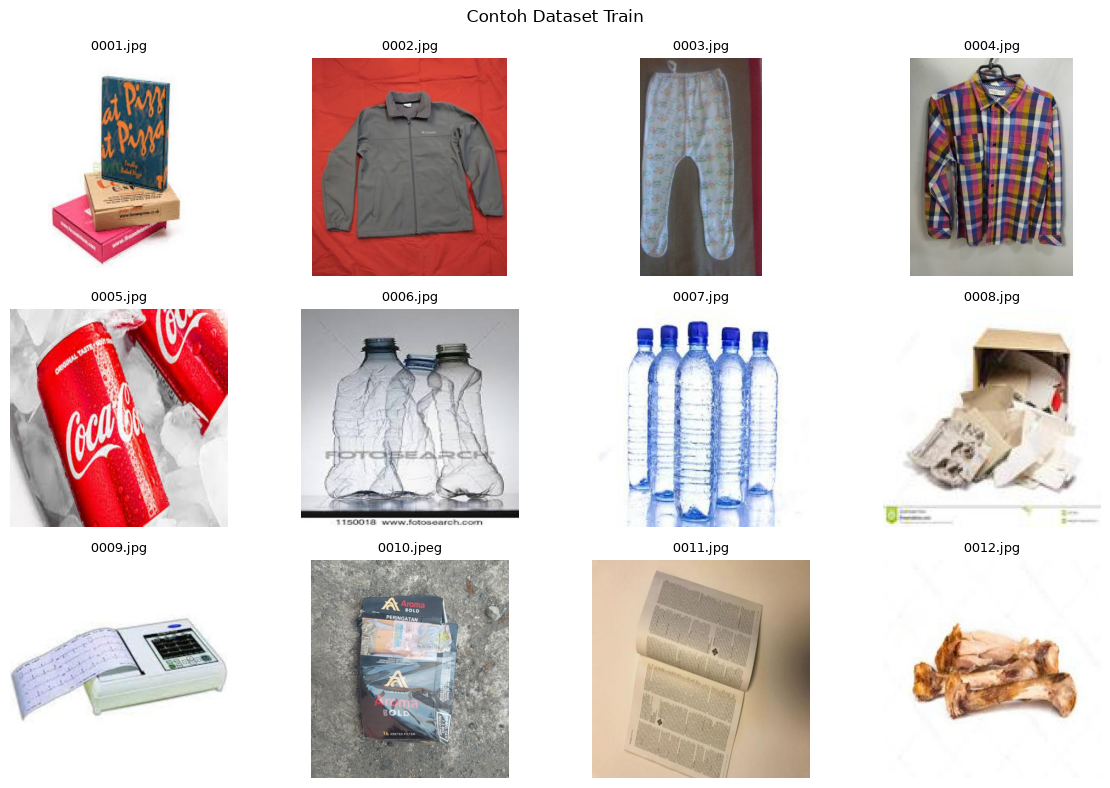

In [10]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(train_paths))):
    img = Image.open(train_paths[i]).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(train_paths[i].name, fontsize=9)
    plt.axis("off")

plt.suptitle("Contoh Dataset Train")
plt.tight_layout()
plt.show()

In [11]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "tensorflow"
])

0

In [12]:
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


In [13]:
feature_extractor = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

feature_extractor.trainable = False

feature_extractor.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
def extract_features(image_paths, batch_size=32):

    all_features = []

    for start in range(0, len(image_paths), batch_size):

        batch_paths = image_paths[start:start + batch_size]

        batch_images = []

        for path in batch_paths:
            img = preprocess_image(path)
            batch_images.append(img)

        batch_images = np.array(batch_images, dtype=np.float32)

        batch_images = preprocess_input(batch_images)

        features = feature_extractor.predict(
            batch_images,
            verbose=0
        )

        all_features.append(features)

    return np.concatenate(all_features, axis=0)

In [15]:
X_train_features = extract_features(train_paths)

print("Ukuran fitur train:", X_train_features.shape)

Ukuran fitur train: (1920, 1280)


In [16]:
X_train_normalized = normalize(X_train_features)

print("Ukuran fitur setelah normalisasi:",
      X_train_normalized.shape)

Ukuran fitur setelah normalisasi: (1920, 1280)


In [17]:
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

train_clusters = kmeans.fit_predict(X_train_normalized)

print("Clustering selesai!")
print("Jumlah cluster:", len(np.unique(train_clusters)))

c:\Users\Danu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


Clustering selesai!
Jumlah cluster: 8


In [18]:
train_cluster_result = pd.DataFrame({
    "filename": [p.name for p in train_paths],
    "cluster": train_clusters
})

print(train_cluster_result.head(10))

    filename  cluster
0   0001.jpg        1
1   0002.jpg        5
2   0003.jpg        5
3   0004.jpg        5
4   0005.jpg        7
5   0006.jpg        5
6   0007.jpg        7
7   0008.jpg        4
8   0009.jpg        0
9  0010.jpeg        1


In [19]:
train_cluster_result.to_csv(
    "train_cluster_results.csv",
    index=False
)

print("Hasil clustering train berhasil disimpan!")

Hasil clustering train berhasil disimpan!


In [20]:
score = silhouette_score(
    X_train_normalized,
    train_clusters,
    sample_size=min(1000, len(X_train_normalized)),
    random_state=42
)

print("Silhouette Score:", score)

Silhouette Score: 0.042520102113485336


In [21]:
def show_cluster_images(cluster_id, jumlah=8):

    indices = np.where(train_clusters == cluster_id)[0]
    selected_indices = indices[:jumlah]

    plt.figure(figsize=(14, 5))

    for i, idx in enumerate(selected_indices):
        img = Image.open(train_paths[idx]).convert("RGB")

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(train_paths[idx].name, fontsize=8)
        plt.axis("off")

    plt.suptitle(
        f"Contoh Gambar Cluster {cluster_id} "
        f"({len(indices)} gambar)"
    )

    plt.tight_layout()
    plt.show()

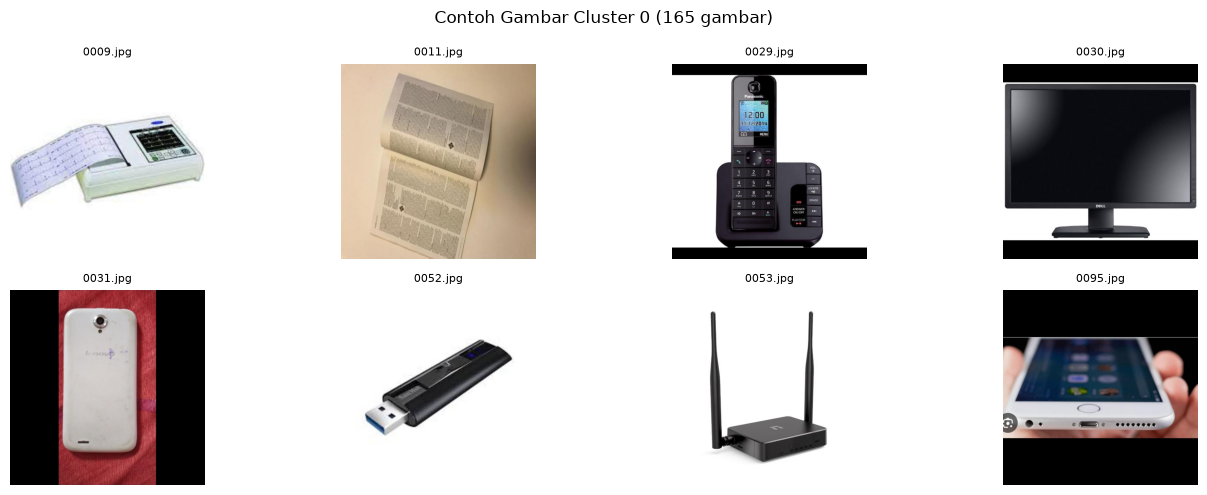

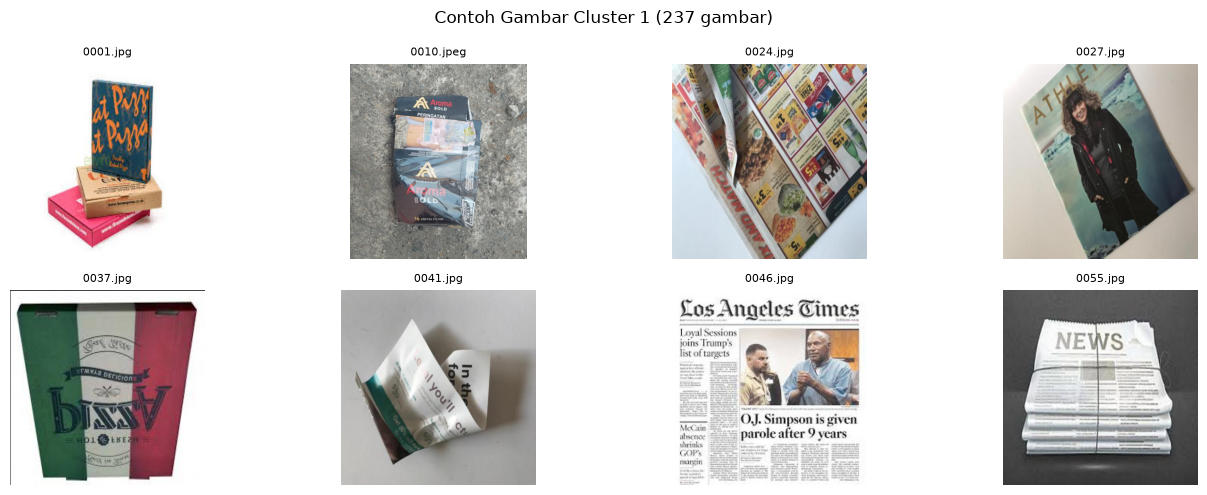

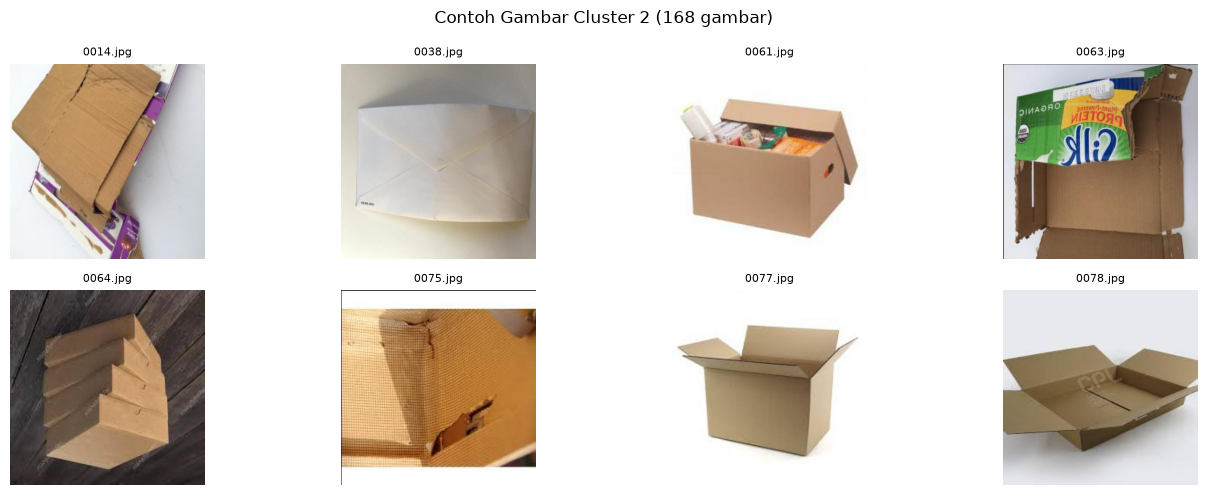

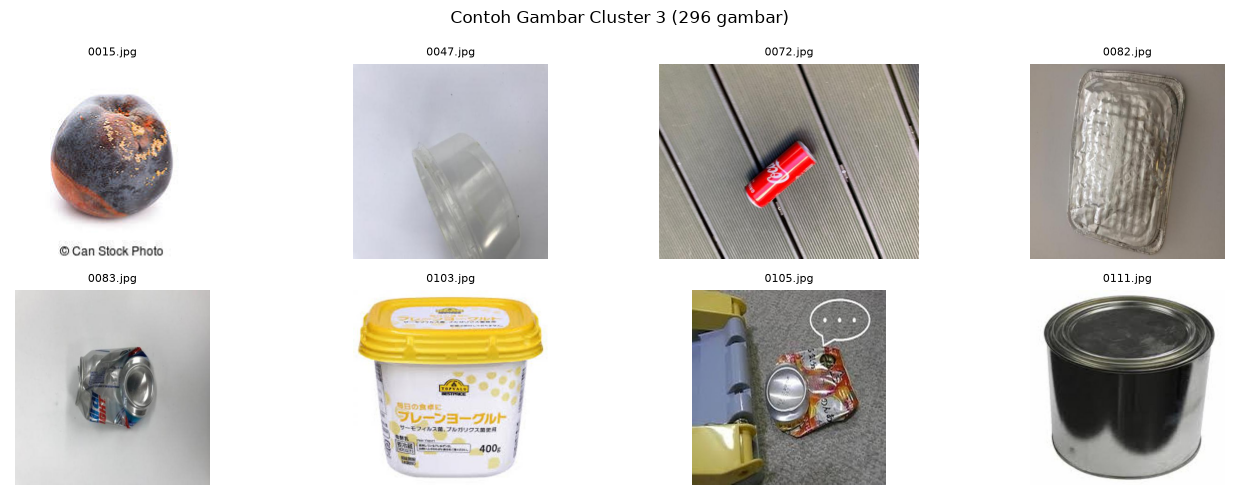

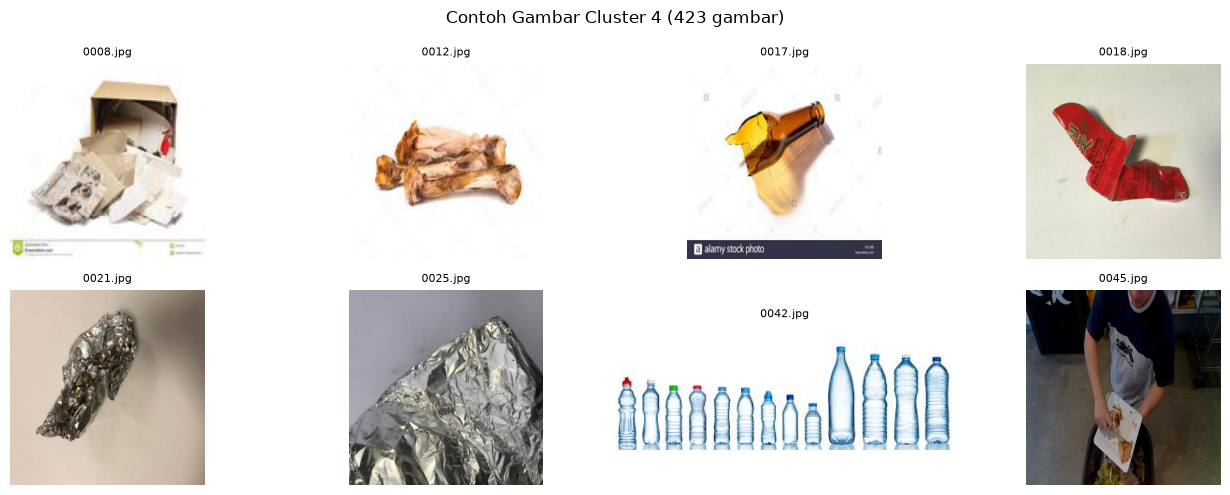

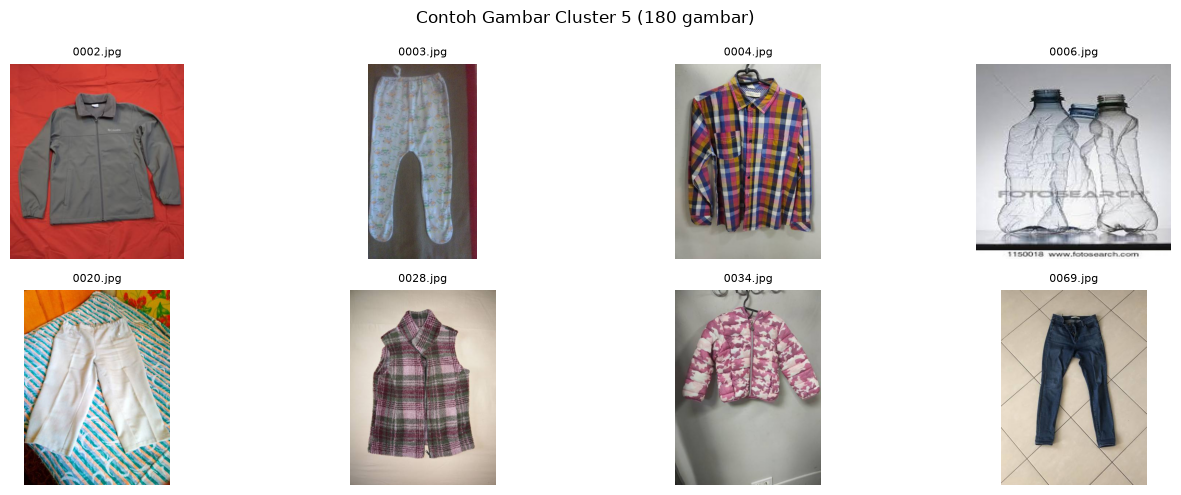

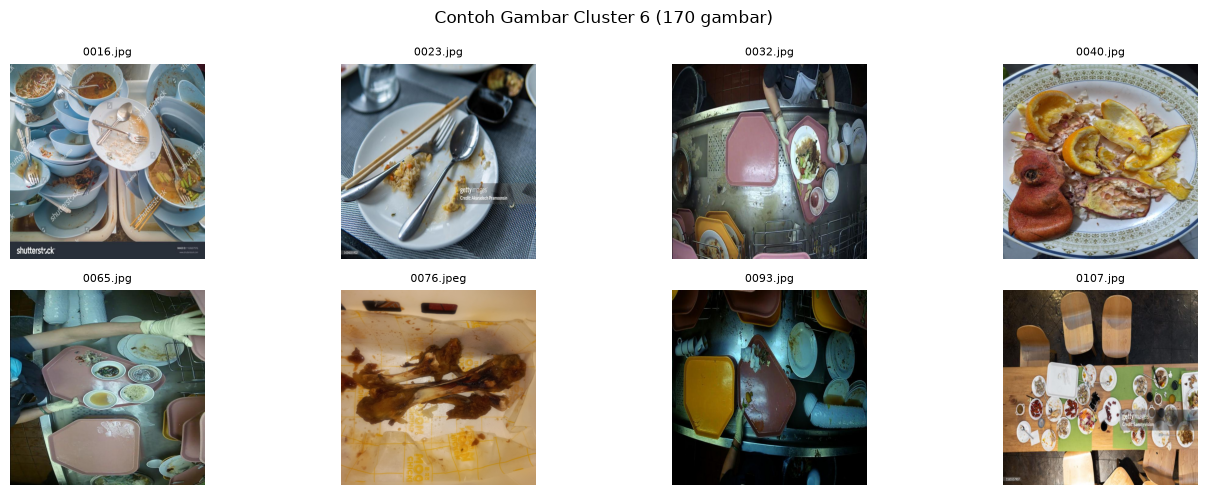

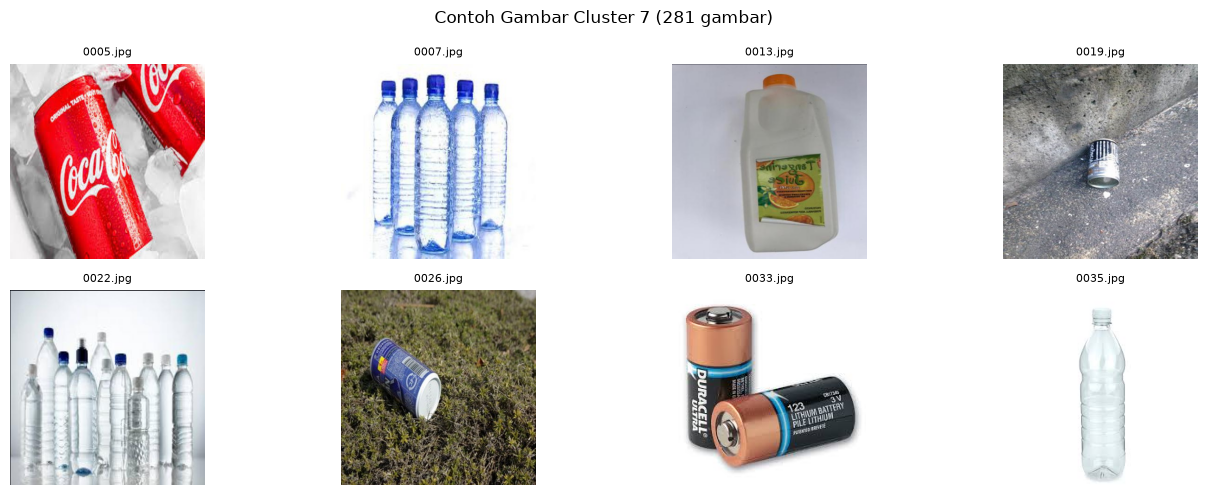

In [22]:
for cluster_id in range(8):
    show_cluster_images(cluster_id)

In [23]:
X_test_features = extract_features(test_paths)

print("Ukuran fitur test:", X_test_features.shape)

Ukuran fitur test: (480, 1280)


In [24]:
X_test_normalized = normalize(X_test_features)

print("Ukuran fitur test setelah normalisasi:",
      X_test_normalized.shape)

Ukuran fitur test setelah normalisasi: (480, 1280)


In [25]:
test_clusters = kmeans.predict(X_test_normalized)

print("Prediksi clustering selesai!")
print("Jumlah gambar test:", len(test_clusters))

Prediksi clustering selesai!
Jumlah gambar test: 480


In [26]:
test_cluster_result = pd.DataFrame({
    "filename": [p.name for p in test_paths],
    "cluster": test_clusters
})

print(test_cluster_result.head(10))

  filename  cluster
0  001.jpg        4
1  002.jpg        6
2  003.jpg        6
3  004.jpg        3
4  005.jpg        1
5  006.jpg        3
6  007.jpg        4
7  008.jpg        2
8  009.jpg        4
9  010.jpg        7


In [27]:
def show_test_cluster(cluster_id, jumlah=8):

    indices = np.where(test_clusters == cluster_id)[0]
    selected_indices = indices[:jumlah]

    plt.figure(figsize=(14, 5))

    for i, idx in enumerate(selected_indices):
        img = Image.open(test_paths[idx]).convert("RGB")

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(test_paths[idx].name, fontsize=8)
        plt.axis("off")

    plt.suptitle(
        f"Test Cluster {cluster_id} "
        f"({len(indices)} gambar)"
    )

    plt.tight_layout()
    plt.show()

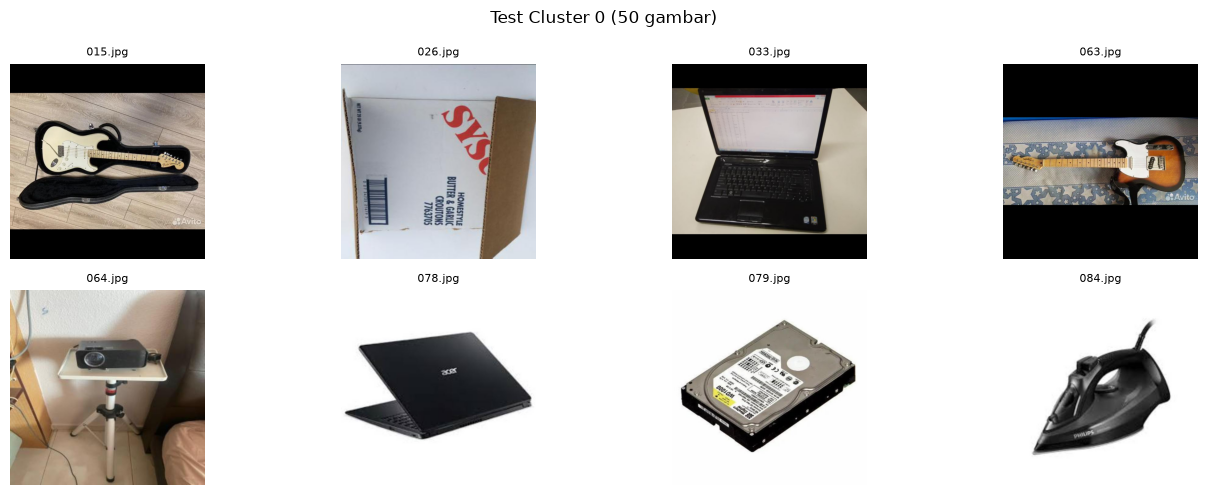

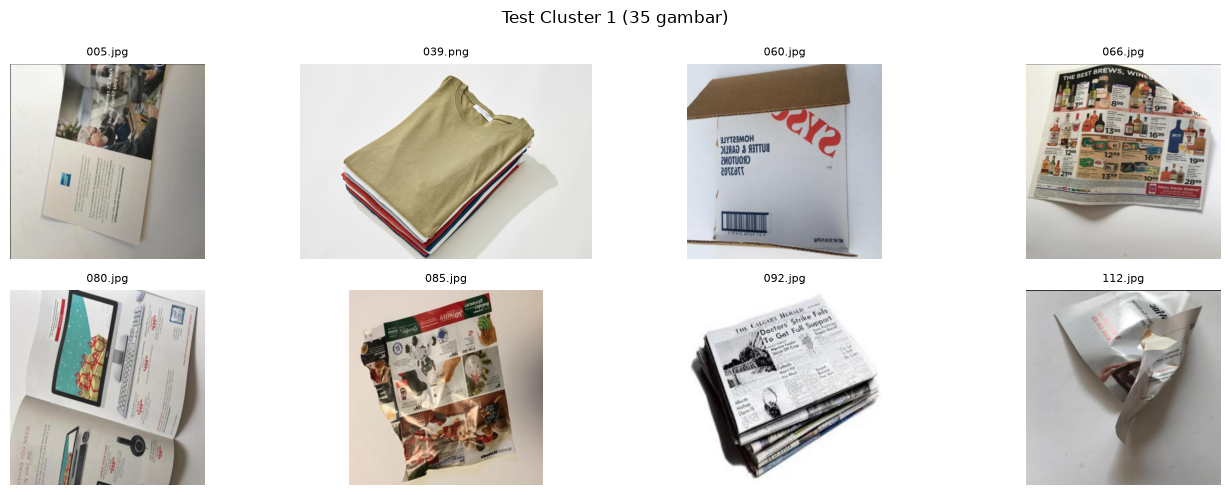

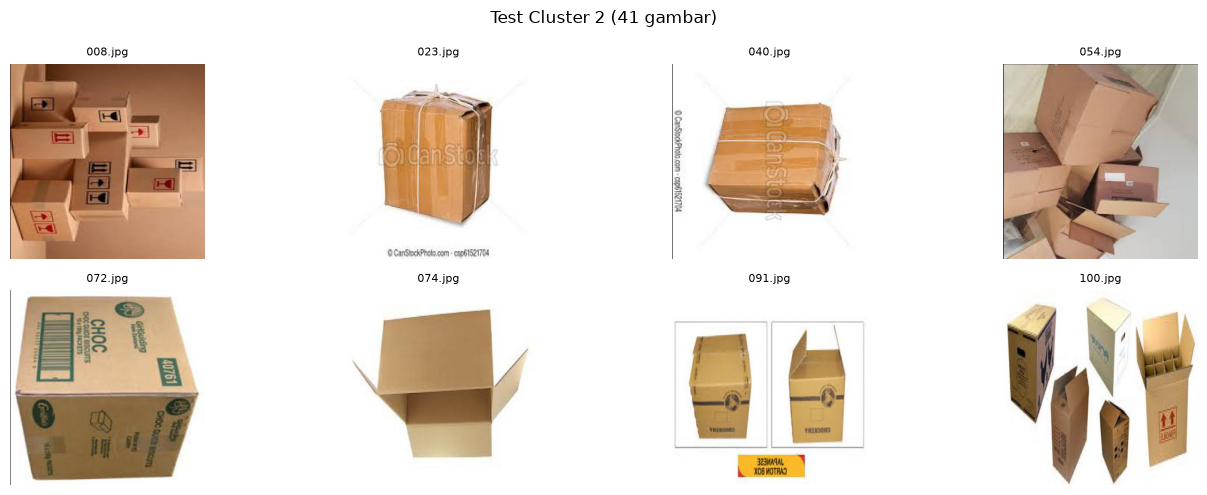

In [ ]:
for cluster_id in range(8):
    show_test_cluster(cluster_id)

In [ ]:
cluster_to_category = {
    0: "plastic",
    1: "paper",
    2: "glass",
    3: "metal",
    4: "cardboard",
    5: "textile",
    6: "electronic",
    7: "foodwaste"
}

In [ ]:
predicted_labels = [
    cluster_to_category[cluster]
    for cluster in test_clusters
]

prediction_result = pd.DataFrame({
    "filename": [p.name for p in test_paths],
    "predicted_label": predicted_labels
})

print(prediction_result.head(10))

  filename predicted_label
0  001.jpg       cardboard
1  002.jpg      electronic
2  003.jpg      electronic
3  004.jpg           metal
4  005.jpg           paper
5  006.jpg           metal
6  007.jpg       cardboard
7  008.jpg           glass
8  009.jpg       cardboard
9  010.jpg       foodwaste
